# W11B · 지시변수의 세 응용을 계산하고 수정하기

회귀분석의 이해 · 2026-11-10 · 주교재6.5–6.7·장말·SAS/R 대응. 자체9개 예, 스키40분기, 교육비150행을 구별합니다. 예상→한 행 계산→실제 함수 수정→결과 해석을 남기세요. 새 성적 반영 과제나 제출 기한은 없습니다.

[온라인 R](https://lunalab-ai.github.io/regre/w11b.html) · [코드를 수정하는 앱](https://lunalab-ai.github.io/regre/apps/w11b/edit/index.html) · [R/QMD](https://github.com/lunalab-ai/regre/tree/2026-fall-w11b/labs/student/w11b)

함수 본문은 src의 실제 정의에서 자동 추출한 동일 초기 코드입니다. 입력·출력과 각 줄의 역할을 본문에서 읽고 직접 수정합니다. 준비 파일은 한 번 불러오며 이후 편집을 몰래 덮어쓰지 않습니다. 모형을 바꿨다면 해당 적합과 이후 셀도 다시 실행하세요.

A편입니다. 다른 노트북 없이 준비부터 독립 실행합니다.

In [ ]:
# Bundled inputs first. A fixed-tag download is used only when no local copy exists.
tag <- "2026-fall-w11b"
local_dirs <- c("data","labs/student/w11b/data","../../labs/student/w11b/data","../../../labs/student/w11b/data")
found <- local_dirs[file.exists(file.path(local_dirs,"indicator-applications-w11b.R"))]
cache_root <- Sys.getenv("REGRE_CACHE_DIR",unset=file.path(path.expand("~"),".cache","regre"))
data_dir <- if(length(found)) found[1] else file.path(cache_root,tag)
dir.create(data_dir,recursive=TRUE,showWarnings=FALSE)
expected <- c("categorical-trace-w11b.R"="cd201e03f0de484b2ee9bb71b7d56e24","indicator-applications-w11b.R"="dcbf19df1dfa8c0618b4577fe649aec5","ski-sales-w11b.csv"="0ccf5e3ffa6992bdb40ba2977addd87c","education-w11b.csv"="8ed5c621f5a02c46ca4654c81d3644d0","fertilizer-w11b.csv"="d9adb09eac8823b7a3d21b0a84b757df")
options(timeout=120)
for(name in names(expected)) {
 target <- file.path(data_dir,name)
 if(!file.exists(target)) {
  status <- download.file(paste0("https://raw.githubusercontent.com/lunalab-ai/regre/",tag,"/labs/student/w11b/data/",name),target,mode="wb")
  if(status!=0) stop("Download failed: check the connection and rerun this preparation cell.")
  cat(name,": fixed-tag download\n")
 } else cat(name,": bundled/cache file\n")
 if(unname(tools::md5sum(target))!=expected[[name]])
  stop("Input bytes differ. Preserve your edited copy and use a fresh data folder/cache.")
}
source(file.path(data_dir,"categorical-trace-w11b.R"),encoding="UTF-8")
source(file.path(data_dir,"indicator-applications-w11b.R"),encoding="UTF-8")
ski_raw <- read.csv(file.path(data_dir,"ski-sales-w11b.csv"))
edu_raw <- read.csv(file.path(data_dir,"education-w11b.csv"))
corn <- read.csv(file.path(data_dir,"fertilizer-w11b.csv"))
toy <- data.frame(source_row=1:9,y=c(4,5,6,6,7,8,8,9,10),Group=factor(rep(c("A","B","C"),each=3),levels=c("C","A","B")))
contrasts(toy$Group) <- contr.treatment(levels(toy$Group),base=1)
ski <- ia_quarter_prepare(ski_raw)
edu <- ia_year_prepare(edu_raw)
stopifnot(nrow(ski)==40,nrow(edu)==150,nrow(corn)==40,all(table(ski$Quarter)==10),all(table(edu$YearGroup)==50))
cat("W11B_DATA_READY: own9 / Ski40 / Education150 / Corn40.\n")
print(R.version.string)

## E01 · 집단의 평균을 회귀식으로 복원

자체 제작9개 값입니다. C를 기준으로 두므로 절편은 C평균, GroupA/B 계수는 C와의 평균 차이입니다. model.matrix의 각 행×계수를 더하면 해당 관측의 적합값입니다.

![집단의 평균을 회귀식으로 복원](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11b/course/notion/w11b/images/w11b-f03.png)
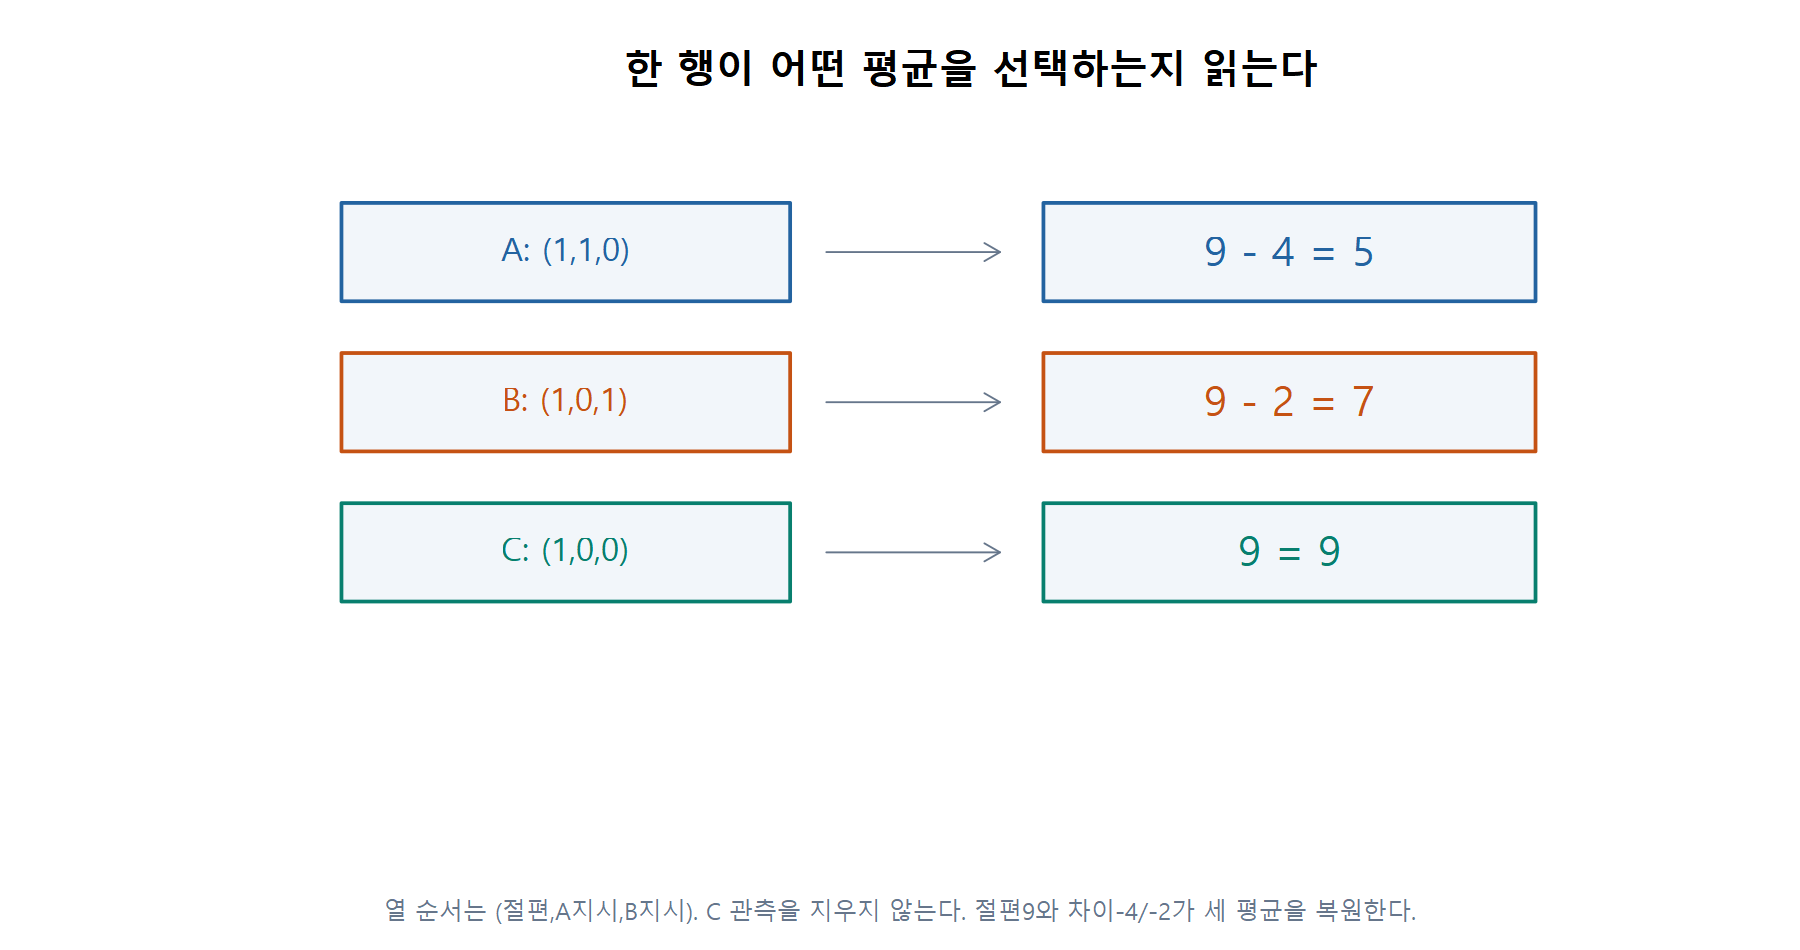

In [ ]:
m0 <- lm(y~1,toy)
m1 <- lm(y~Group,toy)
print(toy);print(model.matrix(m1));print(coef(m1))
print(aggregate(y~Group,toy,mean))

## E02 · 집단내·집단간 변동을 직접 계산

입력은 숫자 벡터 y와 같은 길이의 집단입니다. ave는 각 관측이 속한 집단의 평균을 붙입니다. observed−group_mean을 제곱해 더하면 SSE입니다. 전체 변동은 전체평균에서의 거리로 계산합니다.

![집단내·집단간 변동을 직접 계산](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11b/course/notion/w11b/images/w11b-f04.png)
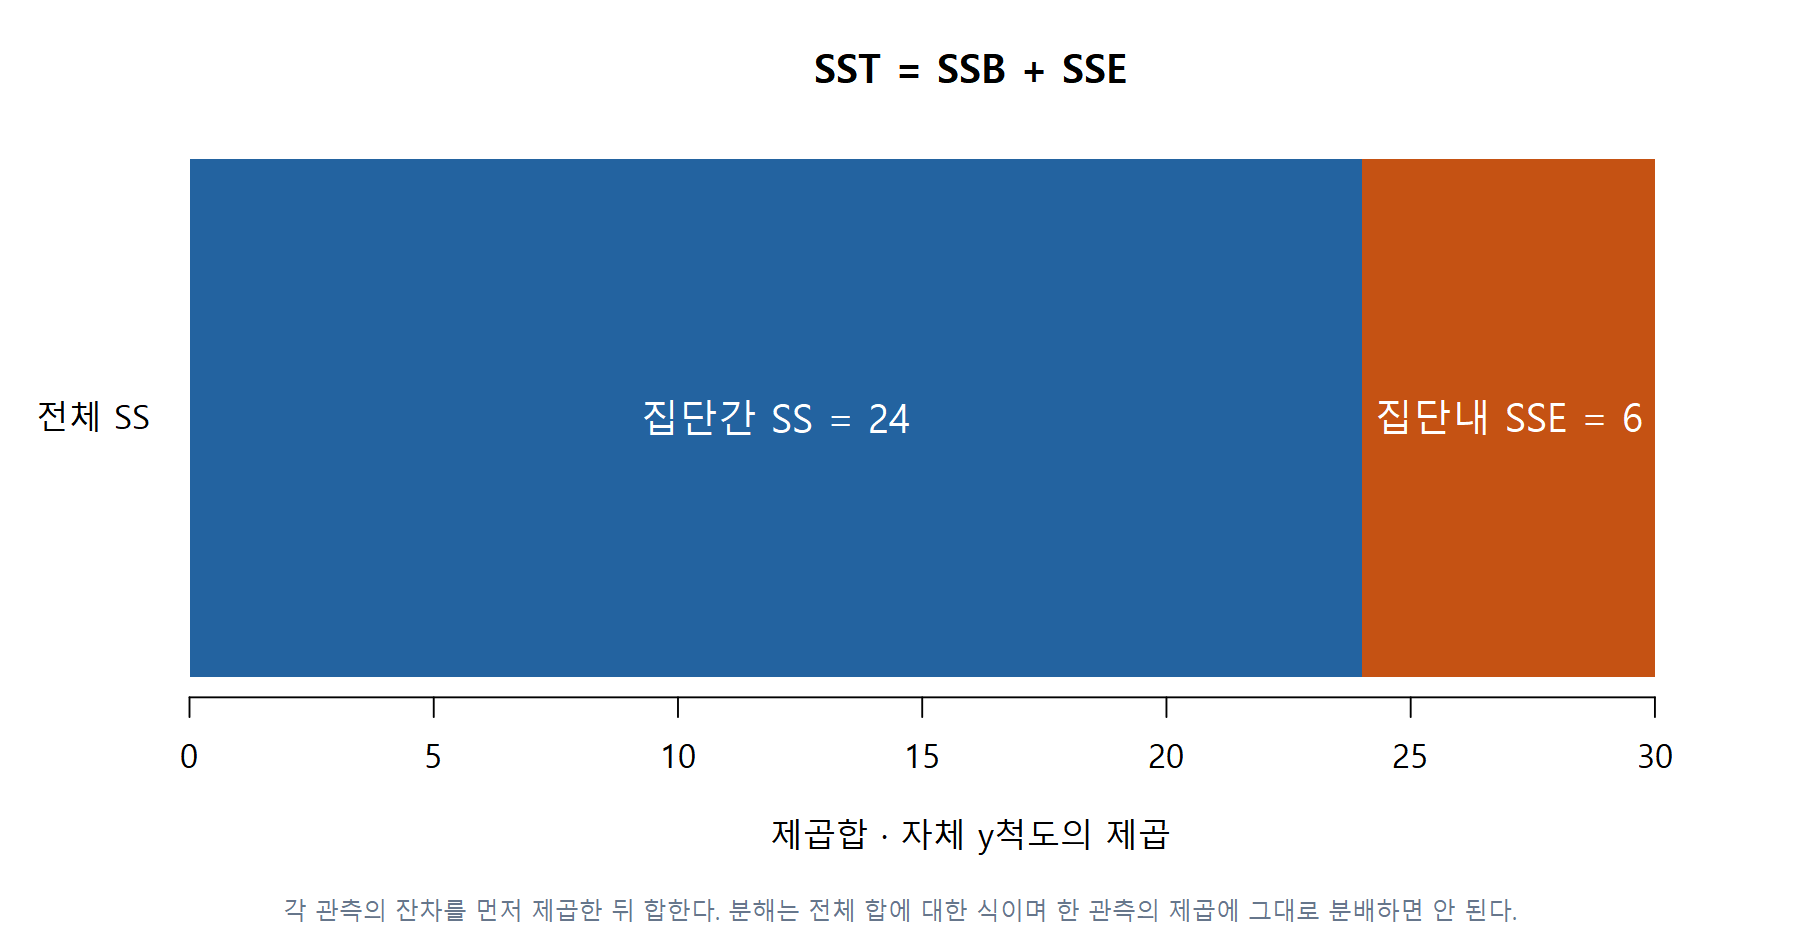

In [ ]:
ia_mean_parts <- function(y, group) {
  if (!is.numeric(y) || any(!is.finite(y)) || length(y)!=length(group) ||
      anyNA(group) || any(!nzchar(as.character(group)))) stop("Use complete numeric y and group labels.")
  g <- droplevels(factor(group)); n <- length(y); k <- nlevels(g)
  if (k<2L || n<=k) stop("Need at least two groups and positive within-group degrees of freedom.")
  grand <- mean(y)
  fitted <- ave(y,g,FUN=mean)
  residual <- y-fitted
  SSE <- sum(residual^2)
  SSB <- sum((fitted-grand)^2)
  SST <- sum((y-grand)^2)
  if (SSE<=0) stop("The classical F ratio needs positive within-group variation.")
  F <- (SSB/(k-1L))/(SSE/(n-k))
  list(rows=data.frame(observed=y,group=g,group_mean=fitted,residual=residual,squared=residual^2),
    summary=data.frame(n=n,k=k,grand=grand,SST=SST,SSB=SSB,SSE=SSE,
      q=k-1L,df=n-k,F=F,p=pf(F,k-1L,n-k,lower.tail=FALSE)))
}
parts <- ia_mean_parts(toy$y,toy$Group)
print(parts$rows);print(parts$summary)
stopifnot(abs(parts$summary$SST-parts$summary$SSB-parts$summary$SSE)<1e-10)
plot(as.numeric(toy$Group),toy$y,pch=19,xaxt="n",xlab="Group (C baseline)",ylab="y (own example)")
axis(1,at=1:3,labels=levels(toy$Group))
points(1:3,tapply(toy$y,toy$Group,mean),pch=18,col="blue",cex=2)

## E03 · QR→예측→잔차→제곱→합

다음은 기존 공통 모듈에서 그대로 추출한 실제 함수입니다. QR로 계수를 구하고 design %*% beta로 적합값을 계산합니다. squared와 cumulative가 어디에서 만들어지는지 읽고 첫 행의 잔차를 확인합니다. 역행렬을 직접 만드는 계산이 아닙니다.

![QR→예측→잔차→제곱→합](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11b/course/notion/w11b/images/w11b-f05.png)
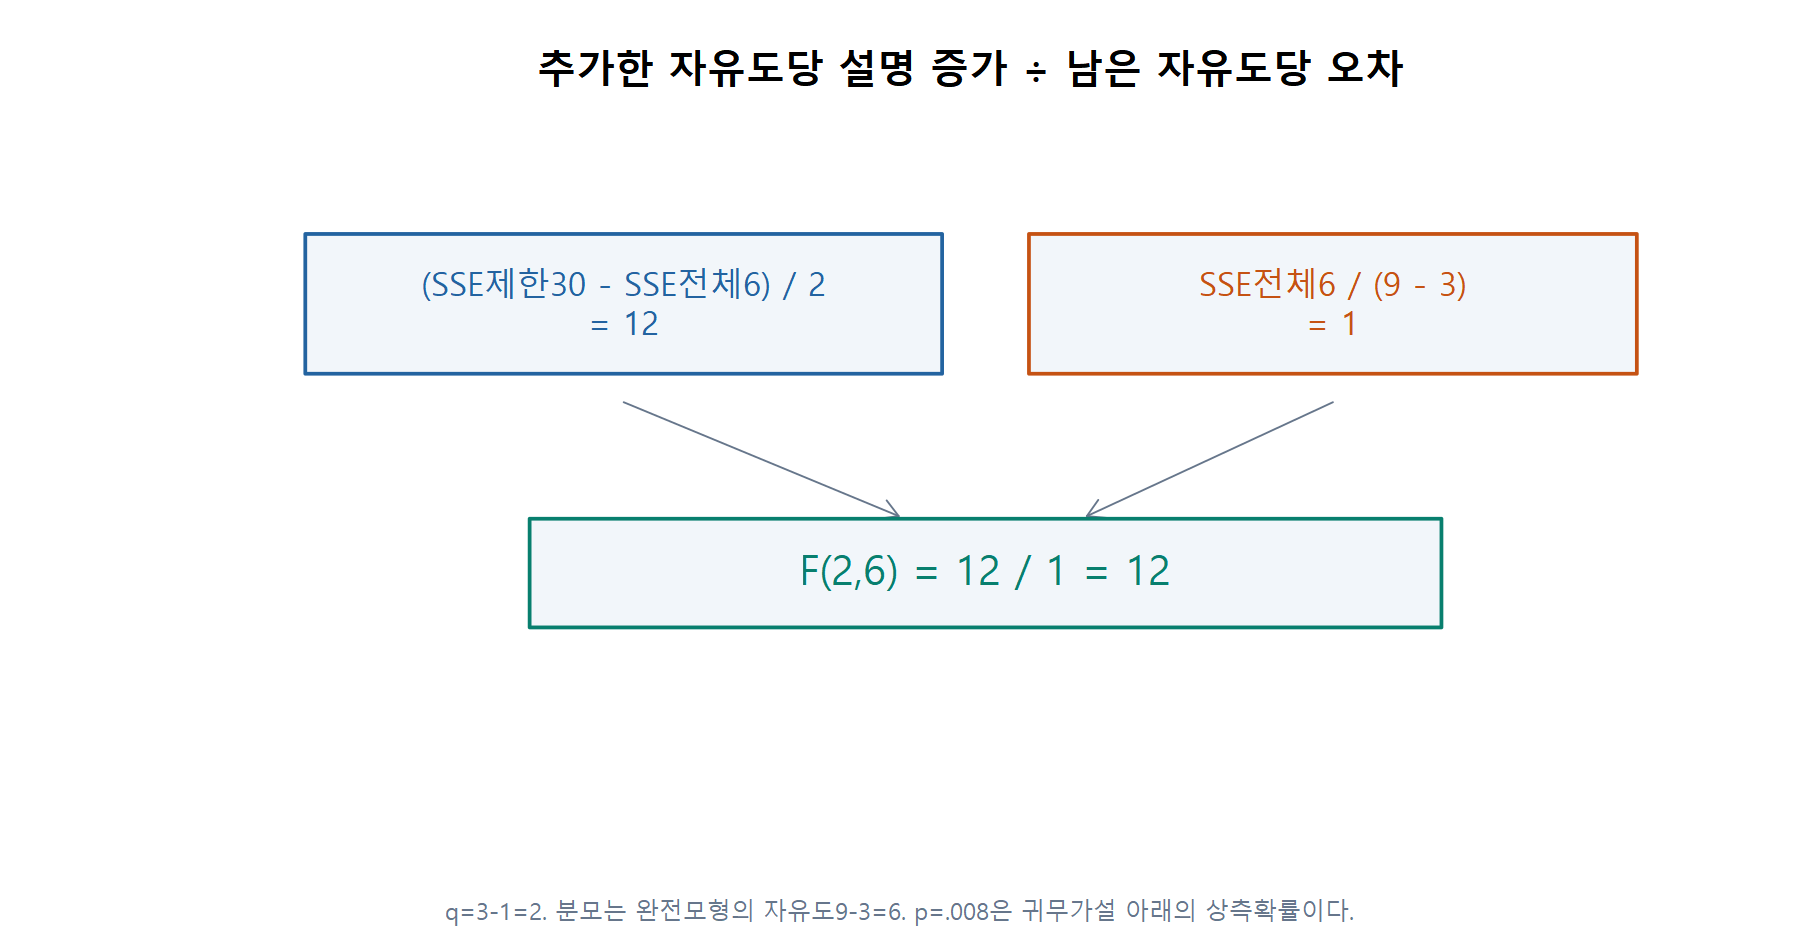

In [ ]:
cat_fit_trace <- function(fit) {
  frame <- cat_check_fit(fit)
  design <- model.matrix(fit)
  observed <- model.response(frame)
  beta <- qr.coef(qr(design),observed)
  fitted <- drop(design %*% beta)
  residual <- observed-fitted
  squared <- residual^2
  rows <- data.frame(source_row=rownames(design),observed=unname(observed),
    fitted=unname(fitted),residual=unname(residual),squared=unname(squared),
    cumulative=cumsum(unname(squared)),row.names=NULL)
  list(design=design,coefficients=beta,rows=rows,
    SSE=sum(squared),n=nrow(design),k=ncol(design),df=df.residual(fit))
}
toy_trace <- cat_fit_trace(m1)
print(toy_trace$rows);print(toy_trace$coefficients)

## E04 · 부분 F의 분자와 분모를 한 줄씩 확인

cat_check_pair가 같은 행ID·반응값·중첩을 확인합니다. SSE 감소를 추가계수 수q로, 완전모형 SSE를 잔차 자유도로 나눈 뒤 비율을 구합니다. pf의 lower.tail=FALSE는 귀무가설 아래에서의 상측확률입니다.

![부분 F의 분자와 분모를 한 줄씩 확인](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11b/course/notion/w11b/images/w11b-f05.png)
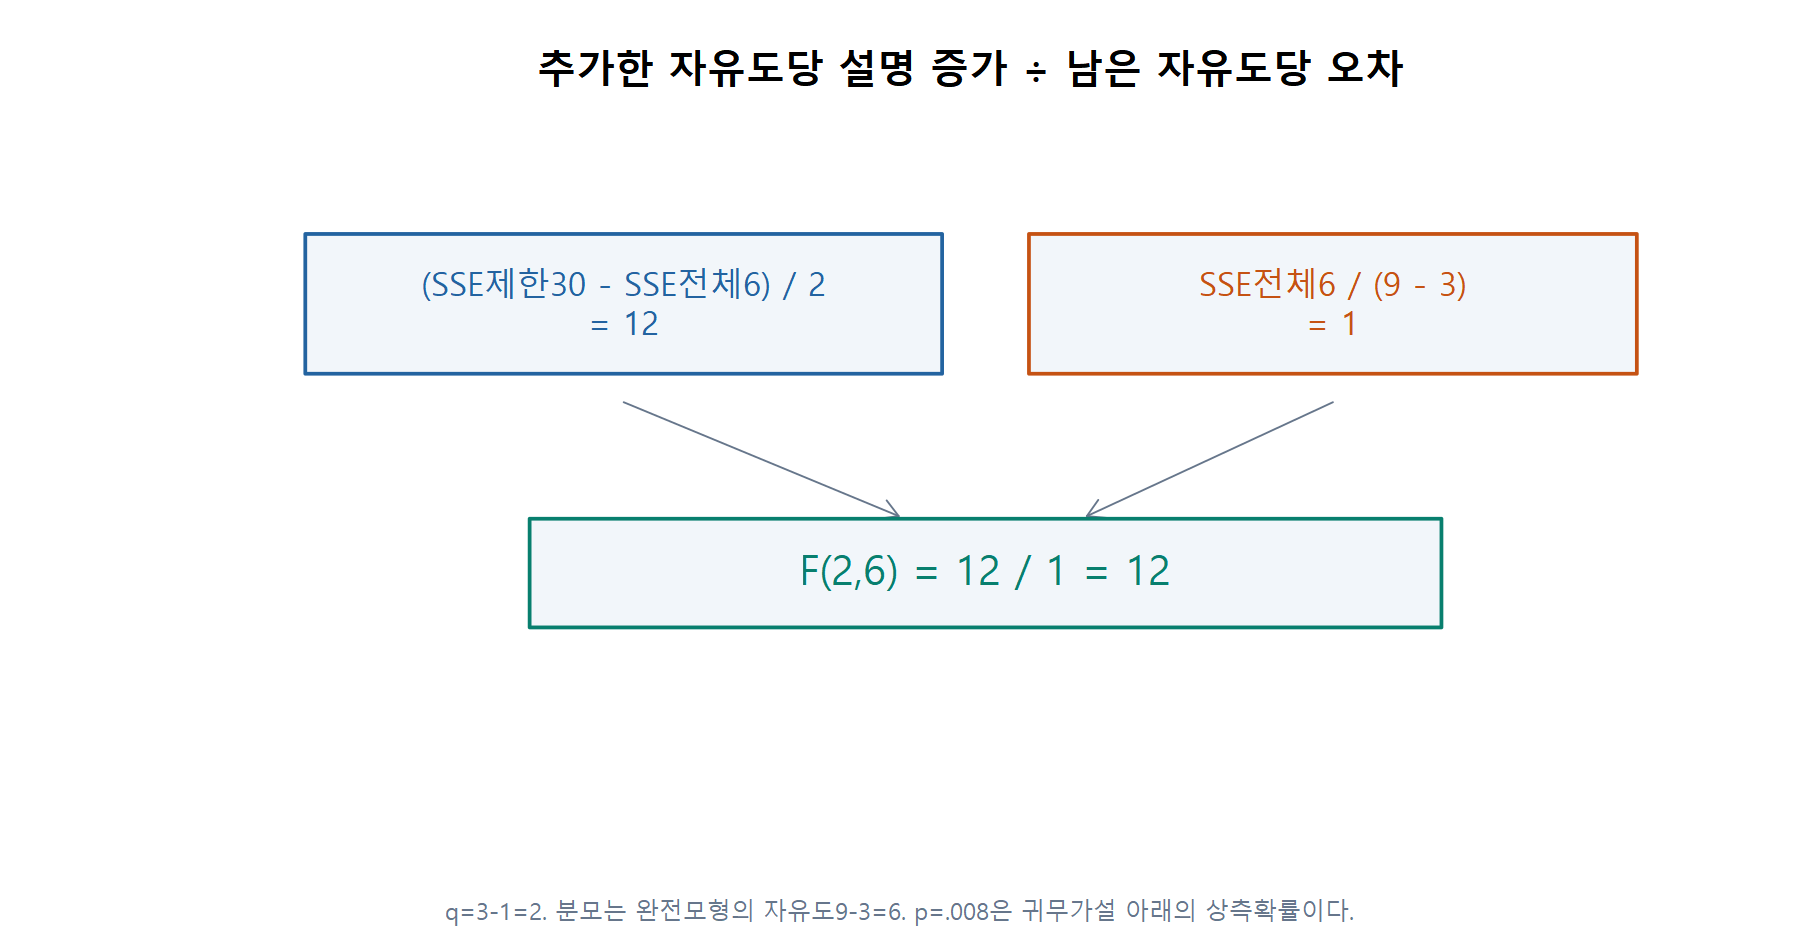

In [ ]:
cat_nested_trace <- function(reduced, full, tolerance=1e-9) {
  checked <- cat_check_pair(reduced,full,tolerance)
  SSE_reduced <- sum(residuals(reduced)^2)
  SSE_full <- sum(residuals(full)^2)
  if (SSE_full<=0 ||
      SSE_reduced<SSE_full-tolerance*max(1,SSE_reduced))
    stop("F needs positive full-model residual variance and a valid nested SSE.")
  q <- checked$q
  df_full <- checked$df_full
  # A tiny negative difference can only be numerical roundoff for nested OLS.
  increase <- max(0,SSE_reduced-SSE_full)
  F <- (increase/q)/(SSE_full/df_full)
  data.frame(n=checked$n,k_reduced=reduced$rank,k_full=full$rank,q=q,
    df_full=df_full,SSE_reduced=SSE_reduced,SSE_full=SSE_full,
    F=F,p=pf(F,q,df_full,lower.tail=FALSE))
}
toy_test <- cat_nested_trace(m0,m1)
print(toy_test);print(anova(m0,m1))

## E05 · 행 순서 대신 Date에서 분기를 읽기

Date가 Q1/64 형태인지 검사한 뒤 두 번째 문자를 분기로 읽습니다. QuarterNumber는 1–4라는 원래 번호, Quarter는 기준4를 제외한 세0/1열을 만드는 factor입니다. 정렬을 바꿔도 같은 날짜는 같은 분기입니다.

![행 순서 대신 Date에서 분기를 읽기](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11b/course/notion/w11b/images/w11b-f06.png)
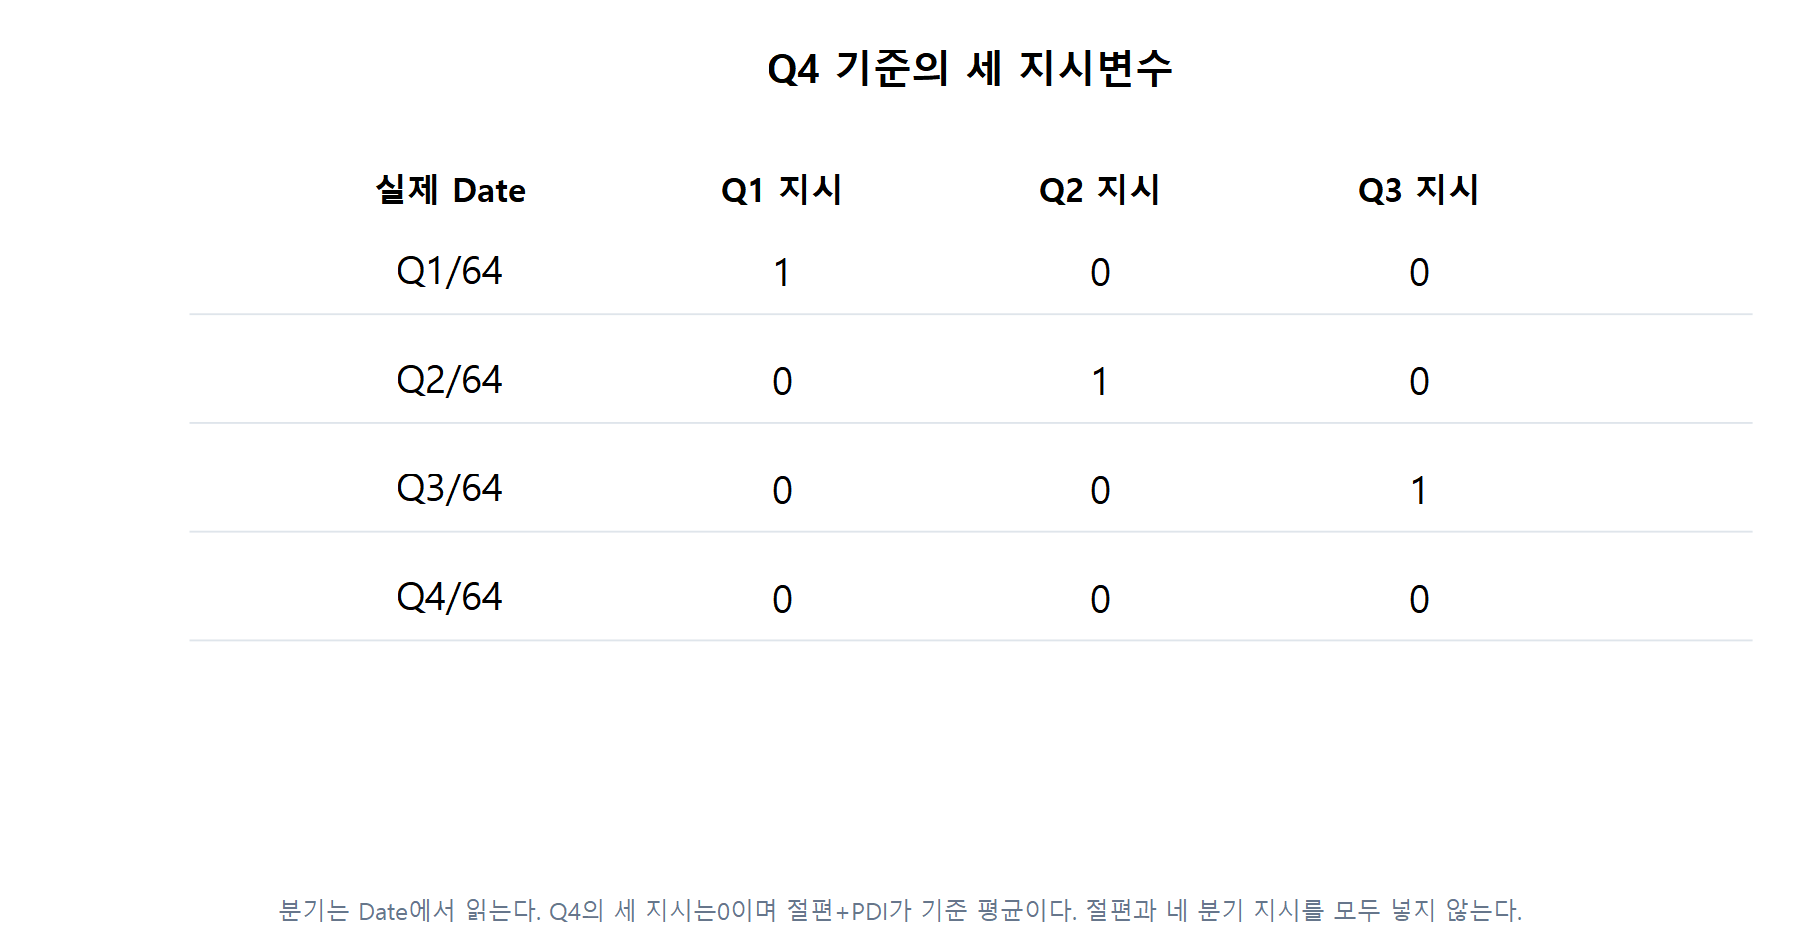

In [ ]:
ia_rows <- function(data, columns) {
  if (!is.data.frame(data) || nrow(data)<2L || !all(columns %in% names(data)))
    stop("Supply a data.frame containing all required columns.")
  if (anyNA(data[columns])) stop("Resolve missing source values explicitly before fitting.")
  d <- data
  if (!"source_row" %in% names(d)) d$source_row <- seq_len(nrow(d))
  if (anyNA(d$source_row) || anyDuplicated(d$source_row)) stop("source_row must be complete and unique.")
  rownames(d) <- as.character(d$source_row)
  d
}
ia_quarter_prepare <- function(data, reference=4L) {
  d <- ia_rows(data,c("Date","Sales","PDI"))
  d$Date <- trimws(as.character(d$Date))
  if (any(!grepl("^Q[1-4]/[0-9]{2}$",d$Date)) || anyDuplicated(d$Date) ||
      !is.numeric(d$Sales) || !is.numeric(d$PDI) || any(!is.finite(c(d$Sales,d$PDI))))
    stop("Use unique Q1/64-style dates and finite numeric Sales/PDI.")
  if (length(reference)!=1L || !reference %in% 1:4) stop("Choose one reference quarter from 1:4.")
  d$QuarterNumber <- as.integer(substr(d$Date,2,2))
  d$Year <- 1900L+as.integer(substr(d$Date,4,5))
  if (!setequal(unique(d$QuarterNumber),1:4)) stop("This four-quarter comparison needs all quarters.")
  d$Quarter <- factor(d$QuarterNumber,levels=c(reference,setdiff(1:4,reference)))
  contrasts(d$Quarter) <- contr.treatment(levels(d$Quarter),base=1)
  d
}
ski <- ia_quarter_prepare(ski_raw,reference=4)
season0 <- lm(Sales~PDI,ski)
season <- lm(Sales~PDI+Quarter,ski)
print(ski[1:8,c("source_row","Date","PDI","QuarterNumber","Quarter")])
print(model.matrix(season)[1:8,]);print(coef(season))

## E06 · 계절 평균과 시간 잔차를 구별

같은40행에서 계절 항 세 개를 추가합니다. 이 비교는 분기별 조건부 평균 차이의 검정입니다. 시간순 잔차와 ACF도 확인합니다. 계절 항을 넣었다는 사실만으로 오차 자기상관이 해결되지는 않습니다.

![계절 평균과 시간 잔차를 구별](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11b/course/notion/w11b/images/w11b-f09.png)
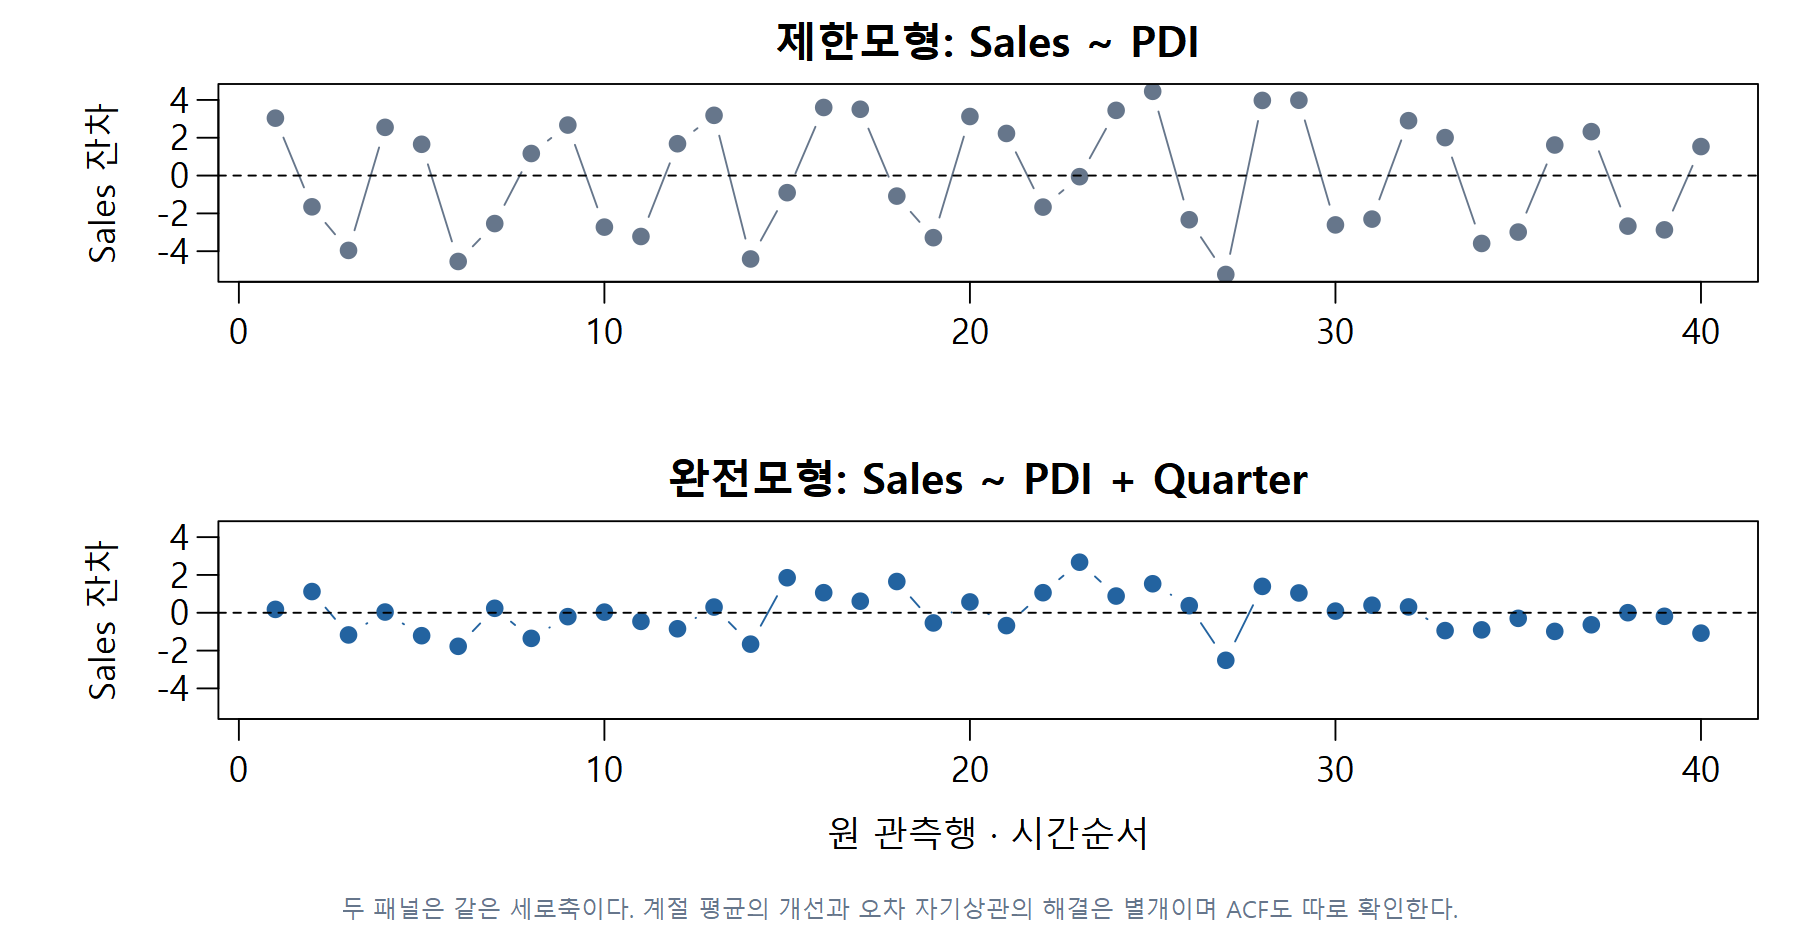

In [ ]:
season_test <- cat_nested_trace(season0,season)
print(season_test);print(anova(season0,season))
plot(ski$source_row,resid(season0),type="b",col="gray50",xlab="Original quarter order",ylab="Sales residual (original scale)")
lines(ski$source_row,resid(season),col="blue",type="b");abline(h=0,lty=2)
acf(resid(season),main="Residual ACF after seasonal mean terms")
ski_ref1 <- ia_quarter_prepare(ski_raw,1)
season_ref1 <- lm(Sales~PDI+Quarter,ski_ref1)
print(max(abs(fitted(season)-fitted(season_ref1))))

### L01 · 기준집단과 한 행

자체9개 예에서 기준을 B로 바꾸고 C집단의 설계행렬 한 행과 평균을 먼저 적으세요. 기준을 바꿀 때 삭제되는 관측이 있는지도 설명하세요.

힌트: 절편 열은1, B이외의 집단 열만 만듭니다.

자가 점검: C의 평균과 전체9개 적합값이 기준변경 전후 같은지 확인합니다.

In [ ]:
my_L01_prediction <- NA_real_
my_L01_reason <- ""

### L02 · 새 값의 제곱합과 F

새 자체 자료 A=(2,4,6), B=(5,7,9), C=(6,8,10)의 집단평균·전체평균·SSE·집단간SS·F를 손으로 계산하고 검산하세요.

힌트: 각 관측−집단평균을 먼저 적습니다.

자가 점검: 전체SS=집단간SS+집단내SS와 자유도2/6을 확인합니다.

In [ ]:
my_L02_prediction <- NA_real_
my_L02_reason <- ""

### L03 · 행을 섞어도 같은 분기

스키 원자료의 행을 뒤집어 준비하세요. Date로 만든 분기와 rep(1:4,10)으로 만든 분기가 언제 어긋나는지 보이세요. Q1기준과 Q4기준의 적합값도 비교하세요.

힌트: 같은 관측은 source_row로 대응합니다.

자가 점검: 같은 Date의 QuarterNumber가 유지되고, 같은 모형의 적합값은 행ID를 맞추면 같습니다.

In [ ]:
my_L03_prediction <- NA_real_
my_L03_reason <- ""

### L04 · 숫자 분기 코딩 디버깅

`Sales ~ PDI + QuarterNumber`와 `Sales ~ PDI + Quarter`의 설계열·계수 수를 비교하세요. 전자의 숨은 제약을 말하고 의도한 분기 모형으로 고치세요.

힌트: 번호의 간격과 범주의 이름은 다릅니다.

자가 점검: 숫자형은 인접 분기 효과가 같은 간격이라는 제약입니다.

In [ ]:
my_L04_prediction <- NA_real_
my_L04_reason <- ""

### L07 · 선택: 두 계절 묶음

Q1/Q4와 Q2/Q3를 두 묶음으로 둔 모형을 네 분기 모형과 비교하세요. 비유의 결과의 의미를 한 문장으로 쓰세요.

힌트: 평균패턴을 단순화한 제한모형입니다.

자가 점검: q2/df35이며 비유의는 두 모형의 동일성 증명이 아닙니다.

In [ ]:
my_L07_prediction <- NA_real_
my_L07_reason <- ""

### L08 · 선택: 같은 n이면 같은 행인가

40행인 두 적합 중 하나의 반응값 또는 관측 순서가 다릅니다. 같은 n만 확인해 부분 F를 계산해도 되는지 설명하고 검사 함수가 거부하는지 확인하세요.

힌트: 행ID·반응값·순서·중첩을 모두 확인합니다.

자가 점검: 의도한 잘못된 비교가 성공처럼 출력되면 안 됩니다.

In [ ]:
my_L08_prediction <- NA_real_
my_L08_reason <- ""

### 실제 입력 검사·행 기여 · cat_check_fit

In [ ]:
cat_check_fit <- function(fit) {
  if (!inherits(fit,"lm") || !is.data.frame(fit$model))
    stop("Use a standard lm with its complete model frame retained.")
  frame <- fit$model
  design <- model.matrix(fit)
  y <- model.response(frame)
  if (!is.numeric(y) || is.matrix(y) || any(!is.finite(y)) ||
      any(!is.finite(design)) || !is.null(model.weights(frame)) ||
      !is.null(model.offset(frame)) || fit$rank!=ncol(design) ||
      df.residual(fit)<1L || any(!is.finite(coef(fit))))
    stop("Require finite, unweighted, no-offset, full-rank univariate OLS with residual df.")
  frame
}

### 실제 입력 검사·행 기여 · cat_check_pair

In [ ]:
cat_check_pair <- function(reduced, full, tolerance=1e-9) {
  r <- cat_check_fit(reduced)
  f <- cat_check_fit(full)
  if (!identical(rownames(r),rownames(f)) ||
      !isTRUE(all.equal(model.response(r),model.response(f),tolerance=0)))
    stop("Compare the same response and identical observations in identical order.")
  xr <- model.matrix(reduced)
  xf <- model.matrix(full)
  if (length(tolerance)!=1L || !is.numeric(tolerance) ||
      !is.finite(tolerance) || tolerance<=0) stop("Use positive finite tolerance.")
  q <- full$rank-reduced$rank
  if (q<=0 || max(abs(qr.resid(qr(xf),xr)))>tolerance*max(1,abs(xr)))
    stop("Reduced design must be nested in full design with fewer parameters.")
  list(n=nrow(f),q=q,df_full=df.residual(full))
}

### 실제 입력 검사·행 기여 · cat_row_trace

In [ ]:
cat_row_trace <- function(fit, newdata) {
  cat_check_fit(fit)
  if (!is.data.frame(newdata) || nrow(newdata)<1L)
    stop("newdata must contain at least one complete observation.")
  term <- delete.response(terms(fit))
  frame <- model.frame(term,newdata,na.action=na.fail,xlev=fit$xlevels)
  design <- model.matrix(term,frame,contrasts.arg=fit$contrasts)
  beta <- coef(fit)
  if (!identical(colnames(design),names(beta)) || any(!is.finite(design)))
    stop("New rows must use the fitted columns, factor levels and finite values.")
  contribution <- sweep(design,2,beta,"*")
  data.frame(row=rep(seq_len(nrow(design)),each=ncol(design)),
    term=rep(colnames(design),times=nrow(design)),
    value=as.vector(t(design)),coefficient=rep(unname(beta),times=nrow(design)),
    contribution=as.vector(t(contribution)),row.names=NULL)
}

In [ ]:
stopifnot(abs(parts$summary$SSE-6)<1e-10,abs(toy_test$F-12)<1e-9,toy_test$q==2,toy_test$df_full==6,
 nrow(ski)==40,season$rank==5,season_test$q==3,season_test$df_full==35,
 abs(season_test$F-anova(season0,season)$F[2])<1e-8,
 max(abs(fitted(season)-fitted(season_ref1)))<1e-9)
cat("W11B_MEAN_SEASON_RUNTIME_PASS: source calculations, not exercise completion\n")